In [1]:
!pip install -U --no-cache-dir \
  "pillow<12" \
  "transformers==4.45.2" \
  "diffusers==0.30.3" \
  "accelerate==0.33.0" \
  "safetensors>=0.4.5" \
  "huggingface-hub>=0.24.6"


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 101.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 75.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 214.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 247.4 MB/s  0:00:00
  Attempting uninstall: pillow
    Found existing installation: pillow 12.0.0
    Uninstalling pillow-12.0.0:
      Successfully uninstalled pillow-12.0.0
  Attempting uninstall: tokenizers━━━━━━━━━━━━━━ 0/5 [pillow]
    Found existing installation: tokenizers 0.22.10/5 [pillow]
    Uninstalling tokenizers-0.22.1:━━━━━━━━━ 0/5 [pillow]
      Successfully uninstalled tokenizers-0.22.1 0/5 [pillow]
  Attempting uninstall: diffusers━━━━━━━━━━━ 0/5 [pillow]
    Found existing installation: diffusers 0.36.00/5 [pillow]
    Uninstalling diffusers-0.36.0:━━━━━━━━━━━━━━━━━━━━━━━ 2/5 [diffusers]
      Successfully uninstalled diffusers-0.36.0━━━━━━━━━━━━━━━ 2/5 [diffusers]
  Attempting uninstall: acce

In [ ]:

import os
import math
import time
import random
from dataclasses import dataclass
from typing import List, Dict, Optional, Tuple
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from tqdm.auto import tqdm
from diffusers import (
    UNet2DConditionModel,
    AutoencoderKL,
    DDPMScheduler,
    DPMSolverMultistepScheduler,
)
from transformers import CLIPTextModel, CLIPTokenizer
try:
    from scipy.ndimage import distance_transform_edt
    HAS_SCIPY = True
except Exception:
    HAS_SCIPY = False

torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
torch.backends.cudnn.benchmark = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("SciPy available:", HAS_SCIPY)


Device: cuda
SciPy available: True


In [2]:
import PIL, transformers, diffusers, accelerate
print("Pillow:", PIL.__version__)
print("Transformers:", transformers.__version__)
print("Diffusers:", diffusers.__version__)
print("Accelerate:", accelerate.__version__)

from diffusers import UNet2DConditionModel, AutoencoderKL, DDPMScheduler
from transformers import CLIPTextModel, CLIPTokenizer
print("✅ Imports OK")


Pillow: 11.3.0
Transformers: 4.45.2
Diffusers: 0.30.3
Accelerate: 0.33.0


2025-12-21 20:03:56.317217: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1766347436.342640    2174 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1766347436.353288    2174 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2025-12-21 20:03:56.559413: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


✅ Imports OK


In [4]:
from dataclasses import dataclass
@dataclass
class Config:
    base_model: str = "runwayml/stable-diffusion-v1-5"

    # ROI + resolution
    image_size: int = 512
    latent_size: int = 64  # SD 512 -> 64
    roi_margin_frac: float = 0.20  # 20% bbox margin around lesion
    min_roi_pixels: int = 24       # skip tiny lesions (in original mask coords)

    # Conditioning
    use_mask_distance: bool = True   # adds distance transforms as extra channels if scipy is available
    # channels = 4 latent + (binary mask + dist_in + dist_out) => 7
    mask_channels: int = 3           # will be auto-adjusted if distance not available
    in_channels_latent: int = 4
    in_channels_unet: int = 7        # set after checking distance availability

    # Text conditioning
    prompt: str = "a realistic clinical photograph of a chronic wound"
    cfg_drop_prob: float = 0.10

    # Training
    lr: float = 1e-5
    weight_decay: float = 1e-2
    batch_size: int = 2
    grad_accum: int = 8              # effective batch = batch_size * grad_accum
    num_workers: int = 4

    max_steps: int = 20000
    mixed_precision: bool = True

    # Min-SNR loss weighting (quality)
    use_min_snr: bool = True
    min_snr_gamma: float = 5.0

    # EMA (quality)
    use_ema: bool = True
    ema_decay: float = 0.9999

    # Sampling
    infer_steps: int = 30
    guidance_scale: float = 5.0
    seed: int = 42

    # Output (save only at end)
    output_dir: str = "wg2diff_roi_final"
    save_ema_weights: bool = True    # usually best for inference

cfg = Config()


In [8]:
import random

def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(cfg.seed)

def mask_bbox(mask_np: np.ndarray) -> Optional[Tuple[int,int,int,int]]:
    """
    mask_np: HxW float in [0,1] or uint8
    returns (x0, y0, x1, y1) inclusive-exclusive bbox, or None if empty
    """
    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        return None
    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1
    return x0, y0, x1, y1

def expand_bbox(x0,y0,x1,y1, w,h, margin_frac: float):
    bw = x1 - x0
    bh = y1 - y0
    mx = int(bw * margin_frac)
    my = int(bh * margin_frac)
    nx0 = max(0, x0 - mx)
    ny0 = max(0, y0 - my)
    nx1 = min(w, x1 + mx)
    ny1 = min(h, y1 + my)
    return nx0, ny0, nx1, ny1


In [9]:
_HAS_SCIPY = False
try:
    from scipy.ndimage import distance_transform_edt
    _HAS_SCIPY = True
except Exception as e:
    print("scipy distance transform not available; will use only binary mask channel.", e)

# Adjust channels
if cfg.use_mask_distance and _HAS_SCIPY:
    cfg.mask_channels = 3  # binary, dist_in, dist_out
else:
    cfg.mask_channels = 1  # binary only

cfg.in_channels_unet = cfg.in_channels_latent + cfg.mask_channels
print("Mask channels:", cfg.mask_channels, "UNet in_channels:", cfg.in_channels_unet)


Mask channels: 3 UNet in_channels: 7


In [10]:
class ROIWoundDataset(Dataset):
    """
    Loads paired (image, mask), crops ROI around lesion, resizes to 512,
    returns:
      pixel_values: [3,512,512] in [-1,1]
      mask_feats:   [C,512,512] in [0,1] (binary + optional distance maps)
    """
    def __init__(self, image_paths: List[str], mask_paths: List[str], cfg: Config):
        assert len(image_paths) == len(mask_paths)
        self.image_paths = image_paths
        self.mask_paths = mask_paths
        self.cfg = cfg

    def __len__(self):
        return len(self.image_paths)

    def _load_rgb(self, path: str) -> Image.Image:
        return Image.open(path).convert("RGB")

    def _load_mask(self, path: str) -> Image.Image:
        return Image.open(path).convert("L")

    def _make_mask_feats(self, mask_01: np.ndarray) -> np.ndarray:
        """
        mask_01: HxW float in [0,1], binary-ish
        returns CxHxW float in [0,1]
        """
        bin_mask = (mask_01 > 0.5).astype(np.float32)

        if self.cfg.mask_channels == 1:
            return bin_mask[None, ...]

        # distance features
        # dist_in: distance to boundary inside lesion
        # dist_out: distance to boundary outside lesion
        # Normalize each to [0,1] (clamped)
        inside = bin_mask.astype(bool)
        outside = ~inside

        dist_in = distance_transform_edt(inside).astype(np.float32)
        dist_out = distance_transform_edt(outside).astype(np.float32)

        # Normalize by max within crop to keep stable scaling
        eps = 1e-6
        dist_in = dist_in / (dist_in.max() + eps)
        dist_out = dist_out / (dist_out.max() + eps)

        feats = np.stack([bin_mask, dist_in, dist_out], axis=0)
        return feats

    def __getitem__(self, idx):
        img = self._load_rgb(self.image_paths[idx])
        msk = self._load_mask(self.mask_paths[idx])

        img_np = np.array(img).astype(np.float32) / 255.0
        msk_np = np.array(msk).astype(np.float32) / 255.0

        h, w = msk_np.shape[:2]
        bb = mask_bbox(msk_np)
        if bb is None:
            # empty mask; you can skip these ahead of time instead
            # return a dummy sample that will be filtered by collate_fn
            return {"skip": True}

        x0,y0,x1,y1 = bb

        # skip tiny lesions in original resolution
        if (x1 - x0) < self.cfg.min_roi_pixels or (y1 - y0) < self.cfg.min_roi_pixels:
            return {"skip": True}

        x0,y0,x1,y1 = expand_bbox(x0,y0,x1,y1, w=w, h=h, margin_frac=self.cfg.roi_margin_frac)

        # Crop
        img_crop = img_np[y0:y1, x0:x1, :]
        msk_crop = msk_np[y0:y1, x0:x1]

        # Resize to 512
        img_crop_pil = Image.fromarray((img_crop * 255).astype(np.uint8)).resize((self.cfg.image_size, self.cfg.image_size), Image.BICUBIC)
        msk_crop_pil = Image.fromarray((msk_crop * 255).astype(np.uint8)).resize((self.cfg.image_size, self.cfg.image_size), Image.NEAREST)

        img_arr = np.array(img_crop_pil).astype(np.float32) / 255.0
        msk_arr = np.array(msk_crop_pil).astype(np.float32) / 255.0

        # SD wants [-1,1]
        img_arr = (img_arr * 2.0) - 1.0

        # Build mask features
        mask_feats = self._make_mask_feats(msk_arr)  # [C,H,W], [0,1]

        # Torch tensors
        pixel_values = torch.from_numpy(img_arr).permute(2,0,1).contiguous()       # [3,512,512]
        mask_feats = torch.from_numpy(mask_feats).contiguous()                    # [C,512,512]

        return {"pixel_values": pixel_values, "mask_feats": mask_feats, "skip": False}


def collate_skip(batch):
    batch = [b for b in batch if not b.get("skip", False)]
    if len(batch) == 0:
        return None
    pixel_values = torch.stack([b["pixel_values"] for b in batch], dim=0)
    mask_feats = torch.stack([b["mask_feats"] for b in batch], dim=0)
    return {"pixel_values": pixel_values, "mask_feats": mask_feats}



In [16]:
import zipfile
from pathlib import Path

p = Path("final_dataset.zip")
print("Exists:", p.exists())
print("Size (GB):", round(p.stat().st_size / (1024**3), 3))

# 1) Check if it's a real ZIP
print("zipfile.is_zipfile:", zipfile.is_zipfile(p))

# 2) Read the first 16 bytes to identify the format ("magic bytes")
with p.open("rb") as f:
    magic = f.read(16)

print("First 16 bytes:", magic)
print("First 16 bytes (hex):", magic.hex(" "))


Exists: True
Size (GB): 1.392
zipfile.is_zipfile: False
First 16 bytes: b'PK\x03\x04\x14\x00\x00\x00\x00\x00K\x8d\x88[\x00\x00'
First 16 bytes (hex): 50 4b 03 04 14 00 00 00 00 00 4b 8d 88 5b 00 00


In [17]:
import zipfile
import os

zip_path = "final_dataset.zip"
out_dir = "final_dataset"

os.makedirs(out_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r", allowZip64=True) as z:
    bad = z.testzip()
    print("Corrupt file:", bad)
    z.extractall(out_dir)

print("Extraction complete")


Corrupt file: None
Extraction complete


In [25]:
import os
from glob import glob

# Your directories
image_dirs = [
    "final_dataset/final_dataset/AZH/",
    "final_dataset/final_dataset/Kaggle_images/",
    "final_dataset/final_dataset/WoundDB/",
]

mask_dirs = [
    "final_dataset/final_dataset/AZH_masks/",
    "final_dataset/final_dataset/Kaggle_Masks/",
    "final_dataset/final_dataset/WoundDB_masks/",
]

# Allowed extensions (adjust if needed)
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
MSK_EXTS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}  # masks often png but keep flexible

def list_image_files(folder: str, exts: set, recursive: bool = False):
    pattern = os.path.join(folder, "**", "*") if recursive else os.path.join(folder, "*")
    paths = glob(pattern, recursive=recursive)
    paths = [p for p in paths if os.path.isfile(p)]
    paths = [p for p in paths if os.path.splitext(p)[1].lower() in exts]
    return sorted(paths)

def build_key(path: str) -> str:
    # base filename without extension
    return os.path.splitext(os.path.basename(path))[0]

image_paths = []
mask_paths = []

for img_dir, msk_dir in zip(image_dirs, mask_dirs):
    imgs = list_image_files(img_dir, IMG_EXTS, recursive=True)
    msks = list_image_files(msk_dir, MSK_EXTS, recursive=True)

    print(f"\nDir: {img_dir}")
    print("  images found:", len(imgs))
    print(f"Dir: {msk_dir}")
    print("  masks  found:", len(msks))

    img_map = {build_key(p): p for p in imgs}
    msk_map = {build_key(p): p for p in msks}

    common = sorted(img_map.keys() & msk_map.keys())
    missing_imgs = sorted(msk_map.keys() - img_map.keys())
    missing_msks = sorted(img_map.keys() - msk_map.keys())

    print("  paired (common keys):", len(common))
    if missing_imgs:
        print("  masks without images (showing up to 5):", missing_imgs[:5])
    if missing_msks:
        print("  images without masks (showing up to 5):", missing_msks[:5])

    image_paths.extend([img_map[k] for k in common])
    mask_paths.extend([msk_map[k] for k in common])

print("\nTOTAL paired samples:", len(image_paths))
print("Example pair:")
if len(image_paths) > 0:
    print("  img:", image_paths[0])
    print("  msk:", mask_paths[0])



Dir: final_dataset/final_dataset/AZH/
  images found: 930
Dir: final_dataset/final_dataset/AZH_masks/
  masks  found: 930
  paired (common keys): 930

Dir: final_dataset/final_dataset/Kaggle_images/
  images found: 2760
Dir: final_dataset/final_dataset/Kaggle_Masks/
  masks  found: 2760
  paired (common keys): 2760

Dir: final_dataset/final_dataset/WoundDB/
  images found: 79
Dir: final_dataset/final_dataset/WoundDB_masks/
  masks  found: 79
  paired (common keys): 79

TOTAL paired samples: 3769
Example pair:
  img: final_dataset/final_dataset/AZH/AZH_00000.png
  msk: final_dataset/final_dataset/AZH_masks/AZH_00000.png


In [26]:
class WG2DiffROI(nn.Module):
    def __init__(self, cfg: Config, device: torch.device):
        super().__init__()
        self.cfg = cfg
        self.device = device

        # Frozen components
        self.vae = AutoencoderKL.from_pretrained(cfg.base_model, subfolder="vae").to(device)
        self.text_encoder = CLIPTextModel.from_pretrained(cfg.base_model, subfolder="text_encoder").to(device)
        self.tokenizer = CLIPTokenizer.from_pretrained(cfg.base_model, subfolder="tokenizer")

        # Trainable UNet
        self.unet = UNet2DConditionModel.from_pretrained(cfg.base_model, subfolder="unet").to(device)

        # Scheduler (train)
        self.train_scheduler = DDPMScheduler.from_pretrained(cfg.base_model, subfolder="scheduler")

        # Modify conv_in to accept 4 + mask_channels
        old = self.unet.conv_in
        new_conv = nn.Conv2d(
            in_channels=cfg.in_channels_unet,
            out_channels=old.out_channels,
            kernel_size=old.kernel_size,
            stride=old.stride,
            padding=old.padding,
        ).to(device)

        # Initialize new conv weights:
        # copy the original 4-channel weights, and init extra channels to small values
        with torch.no_grad():
            new_conv.weight.zero_()
            new_conv.bias.copy_(old.bias)

            # old.weight: [out, in(4), k, k]
            new_conv.weight[:, :cfg.in_channels_latent].copy_(old.weight)
            # extra channels: small init
            if cfg.in_channels_unet > cfg.in_channels_latent:
                nn.init.normal_(new_conv.weight[:, cfg.in_channels_latent:], mean=0.0, std=1e-3)

        self.unet.conv_in = new_conv

        # Freeze VAE + text encoder
        self.vae.requires_grad_(False)
        self.text_encoder.requires_grad_(False)

        self.latent_scaling = 0.18215

    @torch.no_grad()
    def encode_text(self, prompt: str) -> torch.Tensor:
        tokens = self.tokenizer(
            prompt,
            padding="max_length",
            truncation=True,
            max_length=self.tokenizer.model_max_length,
            return_tensors="pt",
        )
        return self.text_encoder(tokens.input_ids.to(self.device)).last_hidden_state

    @torch.no_grad()
    def encode_image_to_latents(self, pixel_values: torch.Tensor) -> torch.Tensor:
        posterior = self.vae.encode(pixel_values).latent_dist
        latents = posterior.sample() * self.latent_scaling
        return latents

    @torch.no_grad()
    def decode_latents_to_image(self, latents: torch.Tensor) -> torch.Tensor:
        latents = latents / self.latent_scaling
        img = self.vae.decode(latents).sample
        img = (img / 2 + 0.5).clamp(0, 1)
        return img

    def maskfeats_to_latent(self, mask_feats_512: torch.Tensor) -> torch.Tensor:
        # mask_feats_512: [B,C,512,512] -> [B,C,64,64]
        return F.interpolate(mask_feats_512, size=(self.cfg.latent_size, self.cfg.latent_size), mode="nearest")


In [27]:
class EMA:
    def __init__(self, model: nn.Module, decay: float):
        self.decay = decay
        self.shadow = {}
        self.collected = {}
        for name, p in model.named_parameters():
            if p.requires_grad:
                self.shadow[name] = p.detach().clone()

    @torch.no_grad()
    def update(self, model: nn.Module):
        for name, p in model.named_parameters():
            if p.requires_grad:
                self.shadow[name].mul_(self.decay).add_(p.detach(), alpha=(1.0 - self.decay))

    def store(self, model: nn.Module):
        self.collected = {}
        for name, p in model.named_parameters():
            if p.requires_grad:
                self.collected[name] = p.detach().clone()

    def copy_to(self, model: nn.Module):
        for name, p in model.named_parameters():
            if p.requires_grad:
                p.data.copy_(self.shadow[name].data)

    def restore(self, model: nn.Module):
        for name, p in model.named_parameters():
            if p.requires_grad:
                p.data.copy_(self.collected[name].data)
        self.collected = {}


In [28]:
def compute_snr_weights(scheduler: DDPMScheduler, timesteps: torch.Tensor, gamma: float) -> torch.Tensor:
    """
    Min-SNR weighting from common diffusion training practice.
    Returns weights shaped [B] to scale the loss per sample.
    """
    alphas_cumprod = scheduler.alphas_cumprod.to(device=timesteps.device)
    a = alphas_cumprod[timesteps]  # [B]
    snr = a / (1 - a)
    # min-SNR weight: min(snr, gamma)/snr
    w = torch.minimum(snr, torch.full_like(snr, gamma)) / snr
    return w


In [29]:
model = WG2DiffROI(cfg, device).to(device)
model.train()

optimizer = torch.optim.AdamW(model.unet.parameters(), lr=cfg.lr, weight_decay=cfg.weight_decay)
scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda" and cfg.mixed_precision))

ema = EMA(model.unet, decay=cfg.ema_decay) if cfg.use_ema else None

# Precompute text embeddings for speed (prompt + empty)
with torch.no_grad():
    text_cond = model.encode_text(cfg.prompt)     # [1,77,768]
    text_uncond = model.encode_text("")           # [1,77,768]

def train_one_batch(batch: Dict) -> torch.Tensor:
    pixel_values = batch["pixel_values"].to(device, non_blocking=True)  # [B,3,512,512] [-1,1]
    mask_feats_512 = batch["mask_feats"].to(device, non_blocking=True)  # [B,C,512,512] [0,1]
    mask_lat = model.maskfeats_to_latent(mask_feats_512)                # [B,C,64,64]

    bsz = pixel_values.shape[0]

    # CFG prompt dropout: some unconditional examples
    use_cond = (torch.rand(bsz, device=device) > cfg.cfg_drop_prob)
    # Build encoder_hidden_states per sample by selecting cond/uncond
    enc = torch.where(
        use_cond[:, None, None],
        text_cond.repeat(bsz, 1, 1),
        text_uncond.repeat(bsz, 1, 1),
    )

    with torch.no_grad():
        latents = model.encode_image_to_latents(pixel_values)  # [B,4,64,64]

    # Timesteps
    timesteps = torch.randint(
        0, model.train_scheduler.config.num_train_timesteps, (bsz,), device=device, dtype=torch.long
    )

    noise = torch.randn_like(latents)
    noisy_latents = model.train_scheduler.add_noise(latents, noise, timesteps)

    # Concatenate mask feats
    unet_in = torch.cat([noisy_latents, mask_lat], dim=1)  # [B,4+C,64,64]

    # Mixed precision forward
    with torch.cuda.amp.autocast(enabled=(cfg.mixed_precision and device.type == "cuda"), dtype=torch.float16):
        noise_pred = model.unet(unet_in, timesteps, encoder_hidden_states=enc).sample

        # base MSE per sample
        mse = (noise_pred - noise) ** 2
        mse = mse.mean(dim=(1,2,3))  # [B]

        if cfg.use_min_snr:
            w = compute_snr_weights(model.train_scheduler, timesteps, cfg.min_snr_gamma)  # [B]
            loss = (w * mse).mean()
        else:
            loss = mse.mean()

    return loss


/tmp/ipykernel_2174/2214929178.py:5: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=(device.type == "cuda" and cfg.mixed_precision))


In [30]:
bad_imgs = [p for p in image_paths if not os.path.isfile(p)]
bad_msks = [p for p in mask_paths if not os.path.isfile(p)]

print("Bad image entries:", len(bad_imgs))
print("Bad mask entries:", len(bad_msks))

if bad_imgs:
    print("Example bad image entry:", bad_imgs[0])
if bad_msks:
    print("Example bad mask entry:", bad_msks[0])

assert len(bad_imgs) == 0 and len(bad_msks) == 0
assert len(image_paths) == len(mask_paths) and len(image_paths) > 0


Bad image entries: 0
Bad mask entries: 0


In [31]:
dataset = ROIWoundDataset(image_paths, mask_paths, cfg)

loader = DataLoader(
    dataset,
    batch_size=cfg.batch_size,
    shuffle=True,
    num_workers=cfg.num_workers,
    pin_memory=True,
    collate_fn=collate_skip,
    drop_last=True,
)

print("Dataset size:", len(dataset))


Dataset size: 3769


In [32]:
os.makedirs(cfg.output_dir, exist_ok=True)

global_step = 0
optimizer.zero_grad(set_to_none=True)

pbar = tqdm(total=cfg.max_steps, desc="Training", dynamic_ncols=True)
running_loss = 0.0
last_log = time.time()

while global_step < cfg.max_steps:
    for batch in loader:
        if batch is None:
            continue

        loss = train_one_batch(batch)
        loss = loss / cfg.grad_accum

        scaler.scale(loss).backward()
        running_loss += loss.item()

        if (global_step + 1) % cfg.grad_accum == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

            if ema is not None:
                ema.update(model.unet)

        global_step += 1
        pbar.update(1)

        if time.time() - last_log > 2.0:
            avg = running_loss / max(1, (pbar.n % 200))
            pbar.set_postfix(loss=f"{avg:.4f}")
            last_log = time.time()

        if global_step >= cfg.max_steps:
            break

pbar.close()
print("Done training.")


Training:   0%|          | 0/20000 [00:00<?, ?it/s]

/tmp/ipykernel_2174/2214929178.py:45: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(enabled=(cfg.mixed_precision and device.type == "cuda"), dtype=torch.float16):


Done training.


In [33]:
@torch.no_grad()
def generate_roi_from_mask(
    model: WG2DiffROI,
    mask_feats_512: torch.Tensor,   # [1,C,512,512] on CPU or GPU
    prompt: str,
    steps: int,
    guidance: float,
    seed: int,
    use_ema: bool = True,
):
    model.eval()
    set_seed(seed)

    # Use a sharper sampler for inference
    sampler = DPMSolverMultistepScheduler.from_config(model.train_scheduler.config)
    sampler.set_timesteps(steps, device=device)

    # Optional: use EMA weights for sampling
    if ema is not None and use_ema:
        ema.store(model.unet)
        ema.copy_to(model.unet)

    # Encode text for CFG
    cond = model.encode_text(prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)  # [2,77,768]

    # Prepare mask features in latent resolution
    if mask_feats_512.device != device:
        mask_feats_512 = mask_feats_512.to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats_512)  # [1,C,64,64]

    # Start from pure noise (fully synthetic)
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        latent_in = torch.cat([latents, latents], dim=0)  # [2,4,64,64]
        mask_in = mask_lat.repeat(2, 1, 1, 1)             # [2,C,64,64]
        unet_in = torch.cat([latent_in, mask_in], dim=1)  # [2,4+C,64,64]

        noise_pred = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise_pred.chunk(2)
        noise = n_u + guidance * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)  # [1,3,512,512] in [0,1]

    if ema is not None and use_ema:
        ema.restore(model.unet)

    return img


In [34]:
def build_mask_feats_from_mask_file(mask_path: str, cfg: Config) -> torch.Tensor:
    """
    Loads a 512x512 ROI mask file, returns [1,C,512,512] float in [0,1].
    If your mask file isn't already ROI-cropped to 512, you should crop the ROI the same way as training.
    """
    m = Image.open(mask_path).convert("L").resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    msk = (np.array(m).astype(np.float32) / 255.0)
    bin_mask = (msk > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None, ...]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        dist_in = distance_transform_edt(inside).astype(np.float32)
        dist_out = distance_transform_edt(outside).astype(np.float32)
        eps = 1e-6
        dist_in = dist_in / (dist_in.max() + eps)
        dist_out = dist_out / (dist_out.max() + eps)
        feats = np.stack([bin_mask, dist_in, dist_out], axis=0)

    feats_t = torch.from_numpy(feats)[None, ...]  # [1,C,512,512]
    return feats_t


In [35]:
final_dir = os.path.join(cfg.output_dir, "final_unet")
os.makedirs(final_dir, exist_ok=True)

# Save EMA weights if enabled and desired (best for inference)
if ema is not None and cfg.save_ema_weights:
    ema.store(model.unet)
    ema.copy_to(model.unet)
    model.unet.save_pretrained(final_dir, safe_serialization=True)
    ema.restore(model.unet)
    print("Saved EMA UNet to:", final_dir)
else:
    model.unet.save_pretrained(final_dir, safe_serialization=True)
    print("Saved UNet to:", final_dir)

# Optionally save the config for reproducibility
with open(os.path.join(cfg.output_dir, "train_config.txt"), "w") as f:
    for k, v in cfg.__dict__.items():
        f.write(f"{k}: {v}\n")
print("Saved config to:", os.path.join(cfg.output_dir, "train_config.txt"))


Saved EMA UNet to: wg2diff_roi_final/final_unet
Saved config to: wg2diff_roi_final/train_config.txt


In [39]:
import numpy as np
from PIL import Image

def full_mask_to_roi_mask(
    mask_path: str,
    cfg,
    return_bbox: bool = False,
):
    """
    Converts a full-image lesion mask into a 512x512 ROI mask,
    using the SAME logic as training.

    Args:
        mask_path: path to full-size mask (any resolution)
        cfg: Config object (uses roi_margin_frac, image_size)
        return_bbox: if True, also returns the ROI bbox in original coords

    Returns:
        roi_mask_512: PIL.Image (L mode, 512x512)
        (optional) bbox: (x0, y0, x1, y1) in original image coords
    """

    # Load full mask
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    # Find lesion bounding box
    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask contains no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    # Expand bbox by margin
    h, w = mask_np.shape
    bw = x1 - x0
    bh = y1 - y0
    mx = int(bw * cfg.roi_margin_frac)
    my = int(bh * cfg.roi_margin_frac)

    x0 = max(0, x0 - mx)
    y0 = max(0, y0 - my)
    x1 = min(w, x1 + mx)
    y1 = min(h, y1 + my)

    # Crop
    mask_crop = mask_np[y0:y1, x0:x1]

    # Resize to 512x512 (NEAREST for masks)
    roi_mask = Image.fromarray((mask_crop * 255).astype(np.uint8))
    roi_mask_512 = roi_mask.resize(
        (cfg.image_size, cfg.image_size),
        Image.NEAREST
    )

    if return_bbox:
        return roi_mask_512, (x0, y0, x1, y1)

    return roi_mask_512


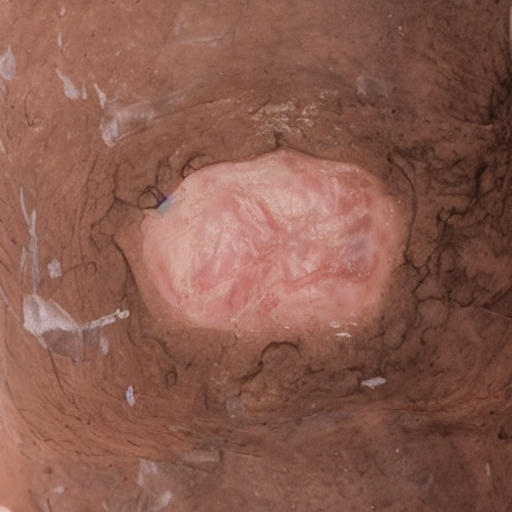

In [40]:
# 1. Convert full mask → ROI mask
roi_mask = full_mask_to_roi_mask("final_dataset/final_dataset/Kaggle_Masks/fusc_0004.png",cfg)

# 2. Save if you want (optional)
roi_mask.save("roi_mask_512.png")

# 3. Build mask features
mask_feats = build_mask_feats_from_mask_file("roi_mask_512.png", cfg)

# 4. Generate synthetic image
img = generate_roi_from_mask(
    model=model,
    mask_feats_512=mask_feats,
    prompt=cfg.prompt,
    steps=cfg.infer_steps,
    guidance=cfg.guidance_scale,
    seed=cfg.seed,
    use_ema=True
)

# 5. View / save result
img_np = (img[0].permute(1,2,0).cpu().numpy() * 255).astype(np.uint8)
Image.fromarray(img_np)


In [44]:
import random
import torch
from PIL import Image

@torch.no_grad()
def generate_roi_from_mask(
    model,
    mask_feats_512,          # [1,C,512,512]
    prompt,
    steps,
    guidance,
    seed=None,               # <-- IMPORTANT: default None
    use_ema=True,
):
    model.eval()

    # Only set seed IF explicitly provided
    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)

    # Use a sharper sampler for inference
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(steps, device=device)

    # Use EMA weights for cleaner output (recommended)
    if ema is not None and use_ema:
        ema.store(model.unet)
        ema.copy_to(model.unet)

    # Encode text for classifier-free guidance
    cond = model.encode_text(prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)  # [2,77,768]

    # Prepare mask features
    if mask_feats_512.device != device:
        mask_feats_512 = mask_feats_512.to(device)

    mask_lat = model.maskfeats_to_latent(mask_feats_512)  # [1,C,64,64]

    # Start from PURE NOISE (fully synthetic)
    latents = torch.randn(
        (1, 4, cfg.latent_size, cfg.latent_size),
        device=device
    )

    for t in sampler.timesteps:
        latent_in = torch.cat([latents, latents], dim=0)  # [2,4,64,64]
        mask_in = mask_lat.repeat(2, 1, 1, 1)             # [2,C,64,64]
        unet_in = torch.cat([latent_in, mask_in], dim=1)  # [2,4+C,64,64]

        noise_pred = model.unet(
            unet_in,
            t,
            encoder_hidden_states=enc
        ).sample

        noise_uncond, noise_cond = noise_pred.chunk(2)
        noise = noise_uncond + guidance * (noise_cond - noise_uncond)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)  # [1,3,512,512]

    # Restore original weights if EMA was used
    if ema is not None and use_ema:
        ema.restore(model.unet)

    return img


In [45]:
img = generate_roi_from_mask(
    model=model,
    mask_feats_512=mask_feats,
    prompt=cfg.prompt,
    steps=cfg.infer_steps,
    guidance=cfg.guidance_scale,
    seed=None,          # <-- this is the key
    use_ema=True
)


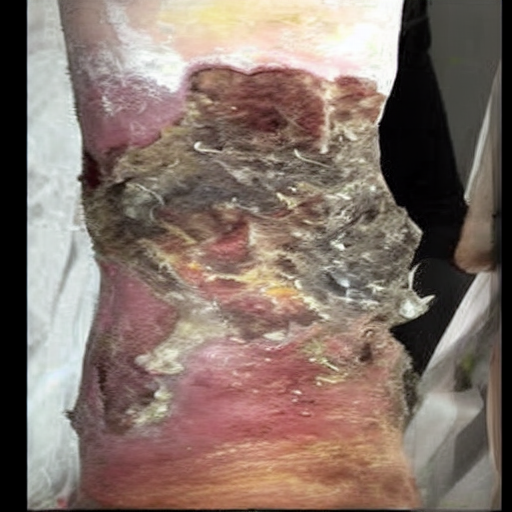

In [46]:
import numpy as np
import torch
from PIL import Image
import random
from scipy.ndimage import distance_transform_edt
from diffusers import DPMSolverMultistepScheduler

# ---------- FULL MASK → ROI MASK ----------
def full_mask_to_roi_mask(mask_path, cfg):
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask has no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    h, w = mask_np.shape
    bw, bh = x1 - x0, y1 - y0
    mx, my = int(bw * cfg.roi_margin_frac), int(bh * cfg.roi_margin_frac)

    x0, y0 = max(0, x0 - mx), max(0, y0 - my)
    x1, y1 = min(w, x1 + mx), min(h, y1 + my)

    crop = mask_np[y0:y1, x0:x1]
    roi_mask = Image.fromarray((crop * 255).astype(np.uint8))
    roi_mask = roi_mask.resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    return roi_mask


# ---------- BUILD MASK FEATURES ----------
def build_mask_feats(mask_pil, cfg):
    mask = np.array(mask_pil).astype(np.float32) / 255.0
    bin_mask = (mask > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        d_in = distance_transform_edt(inside).astype(np.float32)
        d_out = distance_transform_edt(outside).astype(np.float32)
        d_in /= (d_in.max() + 1e-6)
        d_out /= (d_out.max() + 1e-6)
        feats = np.stack([bin_mask, d_in, d_out], axis=0)

    return torch.from_numpy(feats)[None]  # [1,C,512,512]


# ---------- GENERATE IMAGE ----------
@torch.no_grad()
def generate_from_full_mask(model, mask_path, cfg, seed=None):
    model.eval()

    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Convert full mask → ROI mask
    roi_mask = full_mask_to_roi_mask(mask_path, cfg)

    # Build mask features
    mask_feats = build_mask_feats(roi_mask, cfg).to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats)

    # Sampler
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(cfg.infer_steps, device=device)

    # Text embeddings
    cond = model.encode_text(cfg.prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)

    # Start from pure noise
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        lat_in = torch.cat([latents, latents], dim=0)
        mask_in = mask_lat.repeat(2, 1, 1, 1)
        unet_in = torch.cat([lat_in, mask_in], dim=1)

        noise = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + cfg.guidance_scale * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)[0]
    img = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)


# ---------- RUN IT ----------
full_mask_path = "final_dataset/final_dataset/Kaggle_Masks/fusc_0017.png"

out_img = generate_from_full_mask(
    model=model,
    mask_path=full_mask_path,
    cfg=cfg,
    seed=None  # set a number for reproducibility
)

out_img


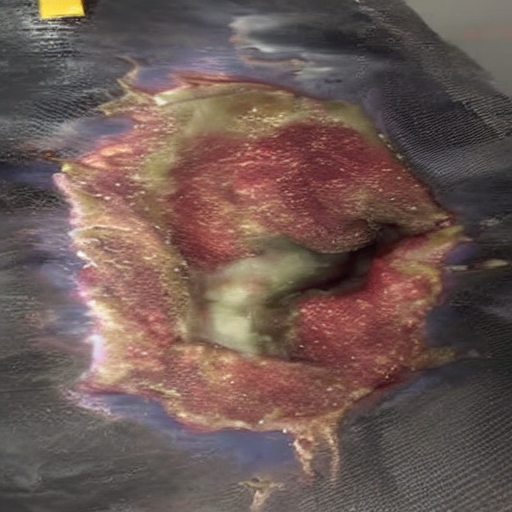

In [47]:
import numpy as np
import torch
from PIL import Image
import random
from scipy.ndimage import distance_transform_edt
from diffusers import DPMSolverMultistepScheduler

# ---------- FULL MASK → ROI MASK ----------
def full_mask_to_roi_mask(mask_path, cfg):
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask has no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    h, w = mask_np.shape
    bw, bh = x1 - x0, y1 - y0
    mx, my = int(bw * cfg.roi_margin_frac), int(bh * cfg.roi_margin_frac)

    x0, y0 = max(0, x0 - mx), max(0, y0 - my)
    x1, y1 = min(w, x1 + mx), min(h, y1 + my)

    crop = mask_np[y0:y1, x0:x1]
    roi_mask = Image.fromarray((crop * 255).astype(np.uint8))
    roi_mask = roi_mask.resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    return roi_mask


# ---------- BUILD MASK FEATURES ----------
def build_mask_feats(mask_pil, cfg):
    mask = np.array(mask_pil).astype(np.float32) / 255.0
    bin_mask = (mask > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        d_in = distance_transform_edt(inside).astype(np.float32)
        d_out = distance_transform_edt(outside).astype(np.float32)
        d_in /= (d_in.max() + 1e-6)
        d_out /= (d_out.max() + 1e-6)
        feats = np.stack([bin_mask, d_in, d_out], axis=0)

    return torch.from_numpy(feats)[None]  # [1,C,512,512]


# ---------- GENERATE IMAGE ----------
@torch.no_grad()
def generate_from_full_mask(model, mask_path, cfg, seed=None):
    model.eval()

    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Convert full mask → ROI mask
    roi_mask = full_mask_to_roi_mask(mask_path, cfg)

    # Build mask features
    mask_feats = build_mask_feats(roi_mask, cfg).to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats)

    # Sampler
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(cfg.infer_steps, device=device)

    # Text embeddings
    cond = model.encode_text(cfg.prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)

    # Start from pure noise
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        lat_in = torch.cat([latents, latents], dim=0)
        mask_in = mask_lat.repeat(2, 1, 1, 1)
        unet_in = torch.cat([lat_in, mask_in], dim=1)

        noise = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + cfg.guidance_scale * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)[0]
    img = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)


# ---------- RUN IT ----------
full_mask_path = "final_dataset/final_dataset/Kaggle_Masks/fusc_0039.png"

out_img = generate_from_full_mask(
    model=model,
    mask_path=full_mask_path,
    cfg=cfg,
    seed=None  # set a number for reproducibility
)

out_img


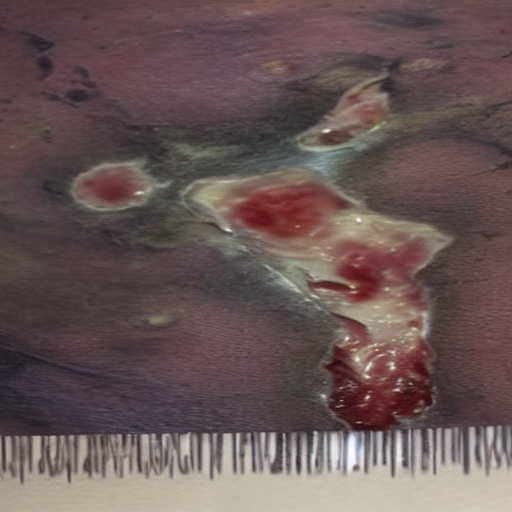

In [48]:
import numpy as np
import torch
from PIL import Image
import random
from scipy.ndimage import distance_transform_edt
from diffusers import DPMSolverMultistepScheduler

# ---------- FULL MASK → ROI MASK ----------
def full_mask_to_roi_mask(mask_path, cfg):
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask has no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    h, w = mask_np.shape
    bw, bh = x1 - x0, y1 - y0
    mx, my = int(bw * cfg.roi_margin_frac), int(bh * cfg.roi_margin_frac)

    x0, y0 = max(0, x0 - mx), max(0, y0 - my)
    x1, y1 = min(w, x1 + mx), min(h, y1 + my)

    crop = mask_np[y0:y1, x0:x1]
    roi_mask = Image.fromarray((crop * 255).astype(np.uint8))
    roi_mask = roi_mask.resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    return roi_mask


# ---------- BUILD MASK FEATURES ----------
def build_mask_feats(mask_pil, cfg):
    mask = np.array(mask_pil).astype(np.float32) / 255.0
    bin_mask = (mask > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        d_in = distance_transform_edt(inside).astype(np.float32)
        d_out = distance_transform_edt(outside).astype(np.float32)
        d_in /= (d_in.max() + 1e-6)
        d_out /= (d_out.max() + 1e-6)
        feats = np.stack([bin_mask, d_in, d_out], axis=0)

    return torch.from_numpy(feats)[None]  # [1,C,512,512]


# ---------- GENERATE IMAGE ----------
@torch.no_grad()
def generate_from_full_mask(model, mask_path, cfg, seed=None):
    model.eval()

    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Convert full mask → ROI mask
    roi_mask = full_mask_to_roi_mask(mask_path, cfg)

    # Build mask features
    mask_feats = build_mask_feats(roi_mask, cfg).to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats)

    # Sampler
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(cfg.infer_steps, device=device)

    # Text embeddings
    cond = model.encode_text(cfg.prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)

    # Start from pure noise
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        lat_in = torch.cat([latents, latents], dim=0)
        mask_in = mask_lat.repeat(2, 1, 1, 1)
        unet_in = torch.cat([lat_in, mask_in], dim=1)

        noise = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + cfg.guidance_scale * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)[0]
    img = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)


# ---------- RUN IT ----------
full_mask_path = "final_dataset/final_dataset/Kaggle_Masks/wsnet_0001.png"

out_img = generate_from_full_mask(
    model=model,
    mask_path=full_mask_path,
    cfg=cfg,
    seed=None  # set a number for reproducibility
)

out_img


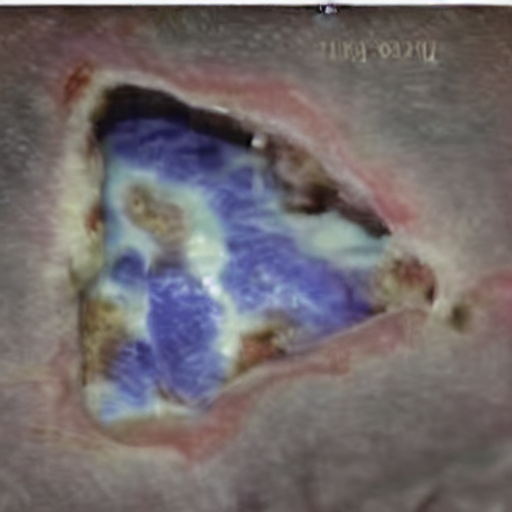

In [49]:
import numpy as np
import torch
from PIL import Image
import random
from scipy.ndimage import distance_transform_edt
from diffusers import DPMSolverMultistepScheduler

# ---------- FULL MASK → ROI MASK ----------
def full_mask_to_roi_mask(mask_path, cfg):
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask has no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    h, w = mask_np.shape
    bw, bh = x1 - x0, y1 - y0
    mx, my = int(bw * cfg.roi_margin_frac), int(bh * cfg.roi_margin_frac)

    x0, y0 = max(0, x0 - mx), max(0, y0 - my)
    x1, y1 = min(w, x1 + mx), min(h, y1 + my)

    crop = mask_np[y0:y1, x0:x1]
    roi_mask = Image.fromarray((crop * 255).astype(np.uint8))
    roi_mask = roi_mask.resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    return roi_mask


# ---------- BUILD MASK FEATURES ----------
def build_mask_feats(mask_pil, cfg):
    mask = np.array(mask_pil).astype(np.float32) / 255.0
    bin_mask = (mask > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        d_in = distance_transform_edt(inside).astype(np.float32)
        d_out = distance_transform_edt(outside).astype(np.float32)
        d_in /= (d_in.max() + 1e-6)
        d_out /= (d_out.max() + 1e-6)
        feats = np.stack([bin_mask, d_in, d_out], axis=0)

    return torch.from_numpy(feats)[None]  # [1,C,512,512]


# ---------- GENERATE IMAGE ----------
@torch.no_grad()
def generate_from_full_mask(model, mask_path, cfg, seed=None):
    model.eval()

    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Convert full mask → ROI mask
    roi_mask = full_mask_to_roi_mask(mask_path, cfg)

    # Build mask features
    mask_feats = build_mask_feats(roi_mask, cfg).to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats)

    # Sampler
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(cfg.infer_steps, device=device)

    # Text embeddings
    cond = model.encode_text(cfg.prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)

    # Start from pure noise
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        lat_in = torch.cat([latents, latents], dim=0)
        mask_in = mask_lat.repeat(2, 1, 1, 1)
        unet_in = torch.cat([lat_in, mask_in], dim=1)

        noise = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + cfg.guidance_scale * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)[0]
    img = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)


# ---------- RUN IT ----------
full_mask_path = "final_dataset/final_dataset/Kaggle_Masks/wsnet_0440.png"

out_img = generate_from_full_mask(
    model=model,
    mask_path=full_mask_path,
    cfg=cfg,
    seed=None  # set a number for reproducibility
)

out_img


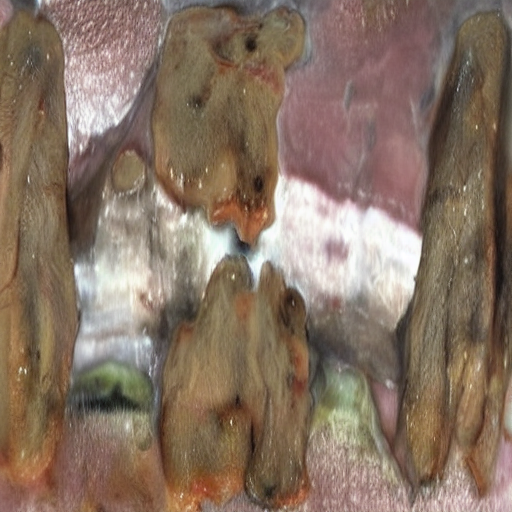

In [51]:
import numpy as np
import torch
from PIL import Image
import random
from scipy.ndimage import distance_transform_edt
from diffusers import DPMSolverMultistepScheduler

# ---------- FULL MASK → ROI MASK ----------
def full_mask_to_roi_mask(mask_path, cfg):
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask has no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    h, w = mask_np.shape
    bw, bh = x1 - x0, y1 - y0
    mx, my = int(bw * cfg.roi_margin_frac), int(bh * cfg.roi_margin_frac)

    x0, y0 = max(0, x0 - mx), max(0, y0 - my)
    x1, y1 = min(w, x1 + mx), min(h, y1 + my)

    crop = mask_np[y0:y1, x0:x1]
    roi_mask = Image.fromarray((crop * 255).astype(np.uint8))
    roi_mask = roi_mask.resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    return roi_mask


# ---------- BUILD MASK FEATURES ----------
def build_mask_feats(mask_pil, cfg):
    mask = np.array(mask_pil).astype(np.float32) / 255.0
    bin_mask = (mask > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        d_in = distance_transform_edt(inside).astype(np.float32)
        d_out = distance_transform_edt(outside).astype(np.float32)
        d_in /= (d_in.max() + 1e-6)
        d_out /= (d_out.max() + 1e-6)
        feats = np.stack([bin_mask, d_in, d_out], axis=0)

    return torch.from_numpy(feats)[None]  # [1,C,512,512]


# ---------- GENERATE IMAGE ----------
@torch.no_grad()
def generate_from_full_mask(model, mask_path, cfg, seed=None):
    model.eval()

    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Convert full mask → ROI mask
    roi_mask = full_mask_to_roi_mask(mask_path, cfg)

    # Build mask features
    mask_feats = build_mask_feats(roi_mask, cfg).to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats)

    # Sampler
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(cfg.infer_steps, device=device)

    # Text embeddings
    cond = model.encode_text(cfg.prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)

    # Start from pure noise
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        lat_in = torch.cat([latents, latents], dim=0)
        mask_in = mask_lat.repeat(2, 1, 1, 1)
        unet_in = torch.cat([lat_in, mask_in], dim=1)

        noise = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + cfg.guidance_scale * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)[0]
    img = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)


# ---------- RUN IT ----------
full_mask_path = "final_dataset/final_dataset/AZH/AZH_00027.png"

out_img = generate_from_full_mask(
    model=model,
    mask_path=full_mask_path,
    cfg=cfg,
    seed=None  # set a number for reproducibility
)

out_img


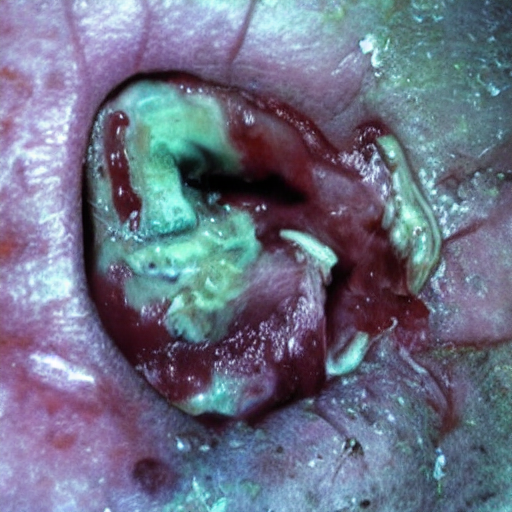

In [52]:
import numpy as np
import torch
from PIL import Image
import random
from scipy.ndimage import distance_transform_edt
from diffusers import DPMSolverMultistepScheduler

# ---------- FULL MASK → ROI MASK ----------
def full_mask_to_roi_mask(mask_path, cfg):
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask has no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    h, w = mask_np.shape
    bw, bh = x1 - x0, y1 - y0
    mx, my = int(bw * cfg.roi_margin_frac), int(bh * cfg.roi_margin_frac)

    x0, y0 = max(0, x0 - mx), max(0, y0 - my)
    x1, y1 = min(w, x1 + mx), min(h, y1 + my)

    crop = mask_np[y0:y1, x0:x1]
    roi_mask = Image.fromarray((crop * 255).astype(np.uint8))
    roi_mask = roi_mask.resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    return roi_mask


# ---------- BUILD MASK FEATURES ----------
def build_mask_feats(mask_pil, cfg):
    mask = np.array(mask_pil).astype(np.float32) / 255.0
    bin_mask = (mask > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        d_in = distance_transform_edt(inside).astype(np.float32)
        d_out = distance_transform_edt(outside).astype(np.float32)
        d_in /= (d_in.max() + 1e-6)
        d_out /= (d_out.max() + 1e-6)
        feats = np.stack([bin_mask, d_in, d_out], axis=0)

    return torch.from_numpy(feats)[None]  # [1,C,512,512]


# ---------- GENERATE IMAGE ----------
@torch.no_grad()
def generate_from_full_mask(model, mask_path, cfg, seed=None):
    model.eval()

    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Convert full mask → ROI mask
    roi_mask = full_mask_to_roi_mask(mask_path, cfg)

    # Build mask features
    mask_feats = build_mask_feats(roi_mask, cfg).to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats)

    # Sampler
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(cfg.infer_steps, device=device)

    # Text embeddings
    cond = model.encode_text(cfg.prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)

    # Start from pure noise
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        lat_in = torch.cat([latents, latents], dim=0)
        mask_in = mask_lat.repeat(2, 1, 1, 1)
        unet_in = torch.cat([lat_in, mask_in], dim=1)

        noise = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + cfg.guidance_scale * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)[0]
    img = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)


# ---------- RUN IT ----------
full_mask_path = "final_dataset/final_dataset/Kaggle_Masks/fusc_0040.png"

out_img = generate_from_full_mask(
    model=model,
    mask_path=full_mask_path,
    cfg=cfg,
    seed=None  # set a number for reproducibility
)

out_img


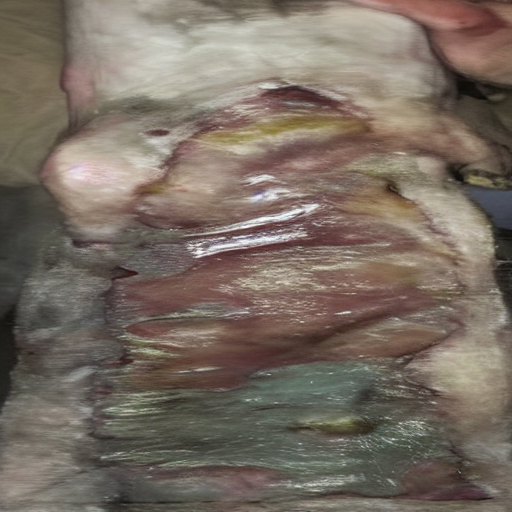

In [53]:
import numpy as np
import torch
from PIL import Image
import random
from scipy.ndimage import distance_transform_edt
from diffusers import DPMSolverMultistepScheduler

# ---------- FULL MASK → ROI MASK ----------
def full_mask_to_roi_mask(mask_path, cfg):
    m = Image.open(mask_path).convert("L")
    mask_np = np.array(m).astype(np.float32) / 255.0

    ys, xs = np.where(mask_np > 0.5)
    if len(xs) == 0:
        raise ValueError("Mask has no lesion pixels")

    x0, x1 = xs.min(), xs.max() + 1
    y0, y1 = ys.min(), ys.max() + 1

    h, w = mask_np.shape
    bw, bh = x1 - x0, y1 - y0
    mx, my = int(bw * cfg.roi_margin_frac), int(bh * cfg.roi_margin_frac)

    x0, y0 = max(0, x0 - mx), max(0, y0 - my)
    x1, y1 = min(w, x1 + mx), min(h, y1 + my)

    crop = mask_np[y0:y1, x0:x1]
    roi_mask = Image.fromarray((crop * 255).astype(np.uint8))
    roi_mask = roi_mask.resize((cfg.image_size, cfg.image_size), Image.NEAREST)
    return roi_mask


# ---------- BUILD MASK FEATURES ----------
def build_mask_feats(mask_pil, cfg):
    mask = np.array(mask_pil).astype(np.float32) / 255.0
    bin_mask = (mask > 0.5).astype(np.float32)

    if cfg.mask_channels == 1:
        feats = bin_mask[None]
    else:
        inside = bin_mask.astype(bool)
        outside = ~inside
        d_in = distance_transform_edt(inside).astype(np.float32)
        d_out = distance_transform_edt(outside).astype(np.float32)
        d_in /= (d_in.max() + 1e-6)
        d_out /= (d_out.max() + 1e-6)
        feats = np.stack([bin_mask, d_in, d_out], axis=0)

    return torch.from_numpy(feats)[None]  # [1,C,512,512]


# ---------- GENERATE IMAGE ----------
@torch.no_grad()
def generate_from_full_mask(model, mask_path, cfg, seed=None):
    model.eval()

    if seed is not None:
        random.seed(seed)
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    # Convert full mask → ROI mask
    roi_mask = full_mask_to_roi_mask(mask_path, cfg)

    # Build mask features
    mask_feats = build_mask_feats(roi_mask, cfg).to(device)
    mask_lat = model.maskfeats_to_latent(mask_feats)

    # Sampler
    sampler = DPMSolverMultistepScheduler.from_config(
        model.train_scheduler.config
    )
    sampler.set_timesteps(cfg.infer_steps, device=device)

    # Text embeddings
    cond = model.encode_text(cfg.prompt)
    uncond = model.encode_text("")
    enc = torch.cat([uncond, cond], dim=0)

    # Start from pure noise
    latents = torch.randn((1, 4, cfg.latent_size, cfg.latent_size), device=device)

    for t in sampler.timesteps:
        lat_in = torch.cat([latents, latents], dim=0)
        mask_in = mask_lat.repeat(2, 1, 1, 1)
        unet_in = torch.cat([lat_in, mask_in], dim=1)

        noise = model.unet(unet_in, t, encoder_hidden_states=enc).sample
        n_u, n_c = noise.chunk(2)
        noise = n_u + cfg.guidance_scale * (n_c - n_u)

        latents = sampler.step(noise, t, latents).prev_sample

    img = model.decode_latents_to_image(latents)[0]
    img = (img.permute(1, 2, 0).cpu().numpy() * 255).astype(np.uint8)
    return Image.fromarray(img)


# ---------- RUN IT ----------
full_mask_path = "final_dataset/final_dataset/AZH/AZH_00050.png"

out_img = generate_from_full_mask(
    model=model,
    mask_path=full_mask_path,
    cfg=cfg,
    seed=None  # set a number for reproducibility
)

out_img
